<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · The compression boundary changes the result

**How much space can we save by batching the same events before compressing them?**
SQL will build two synthetic streams of JSON events, compress individual records
and larger batches, and verify that every byte survives decoding. We will compare
gzip and zstd at their released defaults, then inspect a selected batch size.

The payloads are deliberately constructed: one repeats a fixed string, while the
other uses deterministic digest text for variety. This measures stored byte counts
for these inputs. It is not a latency benchmark or a recommendation for every workload.

## Choose the batch boundary

`EVENTS_PER_BATCH` accepts **1, 8, 32 or 128**. Default **32**; experiment **128**.
Each stream always contains 512 events. We calculate the same four reference
batch sizes, then use this parameter to highlight and summarize one choice.
Restart the kernel and run all after editing.

In [1]:
EVENTS_PER_BATCH = 32

In [2]:
import os
import sys
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = next(
    p
    for p in (Path.cwd(), Path.cwd() / "notebooks", *Path.cwd().parents)
    if (p / "notebook_support.py").is_file()
)
sys.path.insert(0, str(NOTEBOOK_DIR))

In [3]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.patches import Patch
from notebook_support import finish, prose, theme

if (
    isinstance(EVENTS_PER_BATCH, bool)
    or not isinstance(EVENTS_PER_BATCH, int)
    or EVENTS_PER_BATCH not in {1, 8, 32, 128}
):
    raise ValueError("EVENTS_PER_BATCH must be 1, 8, 32 or 128.")
CODEC_COLORS = {"gzip": "#456fba", "zstd": "#267358"}
theme()
con = haybarn.connect(config={"TimeZone": "UTC"})
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/vgi-compress/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/vgi-compress/notebooks/pyproject.toml.

## Connect to the released codecs

VGI downloads and verifies the **v0.4.0** native archive for this platform and
caches it. The notebook needs no local worker build or Rust toolchain. Its Python
environment pins Haybarn **2.0.0rc11**. Initial downloads need network access;
compression itself uses only the synthetic bytes in memory.

The catalog lists supported codecs. We keep this comparison to two framed formats:
**gzip** (default level 6) and **zstd** (default level 3). Compression levels are
codec-specific controls, so their numeric values are not equivalent effort settings.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'compress' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-compress@v0.4.0');
SELECT unnest(compress.main.codecs()) AS codec;

,codec
0,zstd
1,gzip
2,zlib
3,deflate
4,brotli
5,lz4
6,lz4_block
7,snappy
8,snappy_raw
9,xz


## Hold the event bytes constant

Both streams use the same JSON envelope and four-digit sequence strings. Their
payloads are exactly 32 ASCII characters: repeated `ab`, or an MD5 hexadecimal
digest of the sequence number. The digest is only a deterministic source of
varied text here; it does not make the stream random or prove incompressibility.

Every event ends in one newline, included in all byte counts. SQL orders events
explicitly when forming a batch, so changing the batch boundary changes neither
the event content nor its order.

In [5]:
%%sql inputs <<
CREATE OR REPLACE TABLE events AS
SELECT i::INTEGER AS event_id, kind,
       concat('{"device":7,"sequence":"', lpad(i::VARCHAR, 4, '0'),
              '","payload":"', CASE WHEN kind = 'Repeated payload' THEN repeat('ab', 16)
                                   ELSE md5(i::VARCHAR) END, '"}', chr(10)) AS event_line
FROM range(512) t(i)
CROSS JOIN (VALUES ('Repeated payload'), ('Varied payload')) c(kind);
SELECT kind, count(*) AS events, sum(octet_length(event_line::BLOB))::BIGINT AS raw_bytes,
       min(octet_length(event_line::BLOB)) AS smallest_event_bytes,
       max(octet_length(event_line::BLOB)) AS largest_event_bytes
FROM events GROUP BY kind ORDER BY kind;

In [6]:
inputs = globals()["inputs"]
display(inputs)
prose(
    f"Each stream has **{int(inputs.events.iloc[0])} events** and "
    f"**{int(inputs.raw_bytes.iloc[0]):,} raw bytes**. The byte totals are equal, "
    "so their compression difference reflects content structure rather than a larger starting payload."
)

,kind,events,raw_bytes,smallest_event_bytes,largest_event_bytes
0,Repeated payload,512,38912,76,76
1,Varied payload,512,38912,76,76


Each stream has **512 events** and **38,912 raw bytes**. The byte totals are equal, so their compression difference reflects content structure rather than a larger starting payload.

## Compress once for each boundary and codec

The batch ID comes from integer division by the chosen reference size. Each batch
becomes one independent compressed stream. Larger batches can share repeated
structure across events and amortize format overhead, while reducing how finely
we can retrieve or replace a compressed unit.

We materialize the compressed BLOBs. Subsequent summaries and plots reuse these
results; they do not silently recompress the inputs for each chart.

In [7]:
%%sql
CREATE OR REPLACE TABLE batch_sizes AS
SELECT * FROM (VALUES (1), (8), (32), (128)) t(batch_size);
CREATE OR REPLACE TABLE batches AS
SELECT kind, batch_size, (event_id // batch_size)::INTEGER AS batch_id,
       count(*) AS event_count,
       string_agg(event_line, '' ORDER BY event_id)::BLOB AS raw_payload
FROM events CROSS JOIN batch_sizes GROUP BY kind, batch_size, batch_id;
CREATE OR REPLACE TABLE packed AS
SELECT *, compress.main.compress(raw_payload, codec) AS compressed_payload
FROM batches CROSS JOIN (VALUES ('gzip'), ('zstd')) c(codec);
SELECT kind, batch_size, codec, count(*) AS compressed_units,
       sum(event_count) AS represented_events
FROM packed GROUP BY kind, batch_size, codec ORDER BY kind, batch_size, codec;

,kind,batch_size,codec,compressed_units,represented_events
0,Repeated payload,1,gzip,512,512.0
1,Repeated payload,1,zstd,512,512.0
2,Repeated payload,8,gzip,64,512.0
3,Repeated payload,8,zstd,64,512.0
4,Repeated payload,32,gzip,16,512.0
5,Repeated payload,32,zstd,16,512.0
6,Repeated payload,128,gzip,4,512.0
7,Repeated payload,128,zstd,4,512.0
8,Varied payload,1,gzip,512,512.0
9,Varied payload,1,zstd,512,512.0


## Check exact bytes with a bounded decoder

Every decoder call below has an explicit **1 MiB output cap per batch**. Our
synthetic batches are much smaller; a real pipeline should select its cap from
its input contract. Decoding beyond the cap fails explicitly and must not be
treated as an empty successful payload.

We compare complete decoded BLOBs to their original bytes, including newlines.
For these framed formats we can also compare detected and declared codec labels.
Preserve the declared codec when storing payloads: a detector is not a replacement
for format metadata across all codecs.

In [8]:
%%sql checks <<
CREATE OR REPLACE TABLE audited AS
SELECT *, octet_length(raw_payload) AS raw_size,
       octet_length(compressed_payload) AS stored_size,
       compress.main.decompress(compressed_payload, codec, 1048576) AS decoded_payload,
       compress.main.detect_codec(compressed_payload) AS detected_codec,
       compress.main.is_valid(compressed_payload, codec) AS valid_stream
FROM packed;
SELECT 'Exact decoded bytes' AS check_name,
       count(*) FILTER (WHERE decoded_payload IS DISTINCT FROM raw_payload) AS violations FROM audited
UNION ALL
SELECT 'Declared framed codec agrees with detector',
       count(*) FILTER (WHERE detected_codec IS DISTINCT FROM codec) FROM audited
UNION ALL
SELECT 'All streams validate', count(*) FILTER (WHERE valid_stream IS DISTINCT FROM TRUE) FROM audited
UNION ALL
SELECT 'Batches fit the explicit cap', count(*) FILTER (WHERE raw_size > 1048576) FROM audited
UNION ALL
SELECT 'Every event occurs once per scenario', count(*) FROM (
 SELECT kind, codec, batch_size FROM audited GROUP BY kind, codec, batch_size
 HAVING sum(event_count) <> 512 OR count(*) <> 512 // batch_size
)
UNION ALL
SELECT 'Equal raw byte totals across scenarios', count(*) FROM (
 SELECT kind FROM audited GROUP BY kind, codec, batch_size
 HAVING sum(raw_size) <> (SELECT sum(octet_length(event_line::BLOB)) FROM events e WHERE e.kind = audited.kind)
);

In [9]:
checks = globals()["checks"]
display(checks)
assert (checks.violations == 0).all(), (
    "A byte-preservation or batch-accounting check failed."
)
assert inputs.raw_bytes.nunique() == 1
prose(
    f"All **{len(checks)} checks pass**. Each scenario stores the same original bytes "
    "and represents every input event exactly once, so the following totals compare like-for-like payloads."
)

,check_name,violations
0,Exact decoded bytes,0
1,Declared framed codec agrees with detector,0
2,All streams validate,0
3,Batches fit the explicit cap,0
4,Every event occurs once per scenario,0
5,Equal raw byte totals across scenarios,0


All **6 checks pass**. Each scenario stores the same original bytes and represents every input event exactly once, so the following totals compare like-for-like payloads.

In [10]:
%%sql sizes <<
CREATE OR REPLACE TABLE size_summary AS
SELECT kind, codec, batch_size, count(*) AS compressed_units,
       sum(event_count)::BIGINT AS events, sum(raw_size)::BIGINT AS raw_bytes,
       sum(stored_size)::BIGINT AS stored_bytes,
       sum(stored_size)::DOUBLE / sum(raw_size) AS stored_to_raw_ratio,
       sum(stored_size)::DOUBLE / sum(event_count) AS stored_bytes_per_event
FROM audited GROUP BY kind, codec, batch_size;
SELECT * FROM size_summary ORDER BY kind, codec, batch_size;

## The curve describes these measured boundaries

Stored bytes per event includes the codec framing at each batch boundary. The
horizontal axis uses a log base-2 scale; points are the four measured batch sizes.
The two panels share a vertical scale, and the outlined point marks the selected
parameter. Lines connect measured cases, without estimating untested sizes.

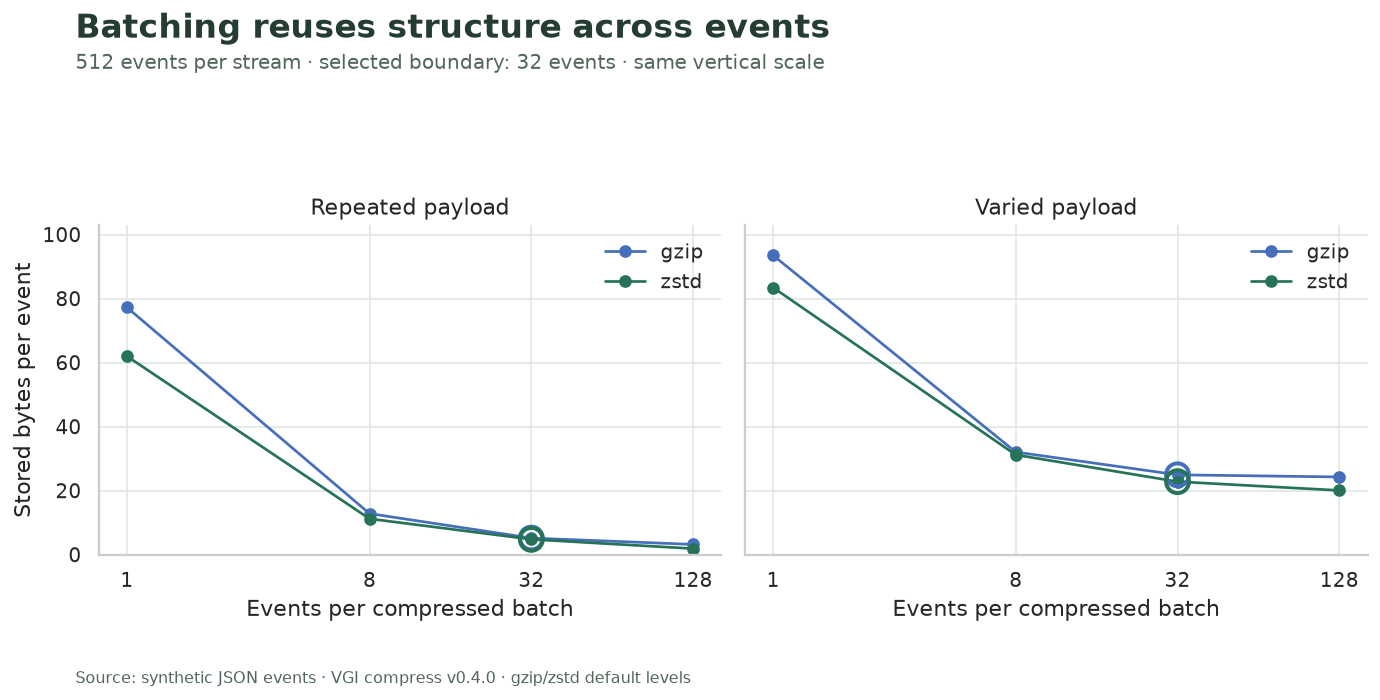

In [11]:
sizes = globals()["sizes"]
kinds = sorted(sizes.kind.unique())
fig, axes = plt.subplots(1, 2, figsize=(11, 5.4), sharey=True)
for ax, kind in zip(axes, kinds, strict=True):
    for codec, color in CODEC_COLORS.items():
        rows = sizes[(sizes.kind == kind) & (sizes.codec == codec)].sort_values(
            "batch_size"
        )
        ax.plot(
            rows.batch_size,
            rows.stored_bytes_per_event,
            marker="o",
            color=color,
            label=codec,
        )
        chosen = rows[rows.batch_size == EVENTS_PER_BATCH].iloc[0]
        ax.scatter(
            [chosen.batch_size],
            [chosen.stored_bytes_per_event],
            s=160,
            facecolors="none",
            edgecolors=color,
            linewidths=2.2,
            zorder=5,
        )
    ax.set_xscale("log", base=2)
    ax.set_xticks([1, 8, 32, 128], labels=["1", "8", "32", "128"])
    ax.set(xlabel="Events per compressed batch", title=kind, ylim=(0, None))
    ax.legend(frameon=False)
axes[0].set_ylim(0, float(sizes.stored_bytes_per_event.max()) * 1.10)
axes[0].set_ylabel("Stored bytes per event")
finish(
    fig,
    "Batching reuses structure across events",
    f"512 events per stream · selected boundary: {EVENTS_PER_BATCH} events · same vertical scale",
    "bytes-per-event.png",
)

## How much does the selected boundary change storage?

The baseline compresses each event separately with the same codec. The selected
case changes only its batch boundary. Totals below include compressed payloads,
not database row headers, indexes or transport envelopes. **1 KiB = 1,024 bytes.**

In [12]:
%%sql comparison <<
SELECT chosen.kind, chosen.codec, chosen.compressed_units, chosen.raw_bytes,
       baseline.stored_bytes AS individual_bytes, chosen.stored_bytes AS batched_bytes,
       baseline.stored_bytes - chosen.stored_bytes AS bytes_saved,
       100.0 * (baseline.stored_bytes - chosen.stored_bytes) / baseline.stored_bytes AS saved_pct
FROM size_summary chosen JOIN size_summary baseline USING (kind, codec)
WHERE chosen.batch_size = {{ EVENTS_PER_BATCH }} AND baseline.batch_size = 1
ORDER BY chosen.kind, chosen.codec;

In [13]:
comparison = globals()["comparison"]
display(comparison)
best = comparison.sort_values(
    ["saved_pct", "kind", "codec"], ascending=[False, True, True]
).iloc[0]
prose(
    f"At **{EVENTS_PER_BATCH} events per batch**, each stream becomes "
    f"**{int(comparison.compressed_units.iloc[0])} compressed units** instead of 512. "
    f"The largest measured saving relative to one-event compression is "
    f"**{best.saved_pct:.1f}%** for **{best['kind']} / {best.codec}**. "
    "These savings come with a larger decode/replacement unit; latency and access patterns need a separate evaluation."
)

,kind,codec,compressed_units,raw_bytes,individual_bytes,batched_bytes,bytes_saved,saved_pct
0,Repeated payload,gzip,16,38912,39551,2652,36899,93.294733
1,Repeated payload,zstd,16,38912,31744,2447,29297,92.291457
2,Varied payload,gzip,16,38912,47871,12769,35102,73.326231
3,Varied payload,zstd,16,38912,42725,11676,31049,72.671738


At **32 events per batch**, each stream becomes **16 compressed units** instead of 512. The largest measured saving relative to one-event compression is **93.3%** for **Repeated payload / gzip**. These savings come with a larger decode/replacement unit; latency and access patterns need a separate evaluation.

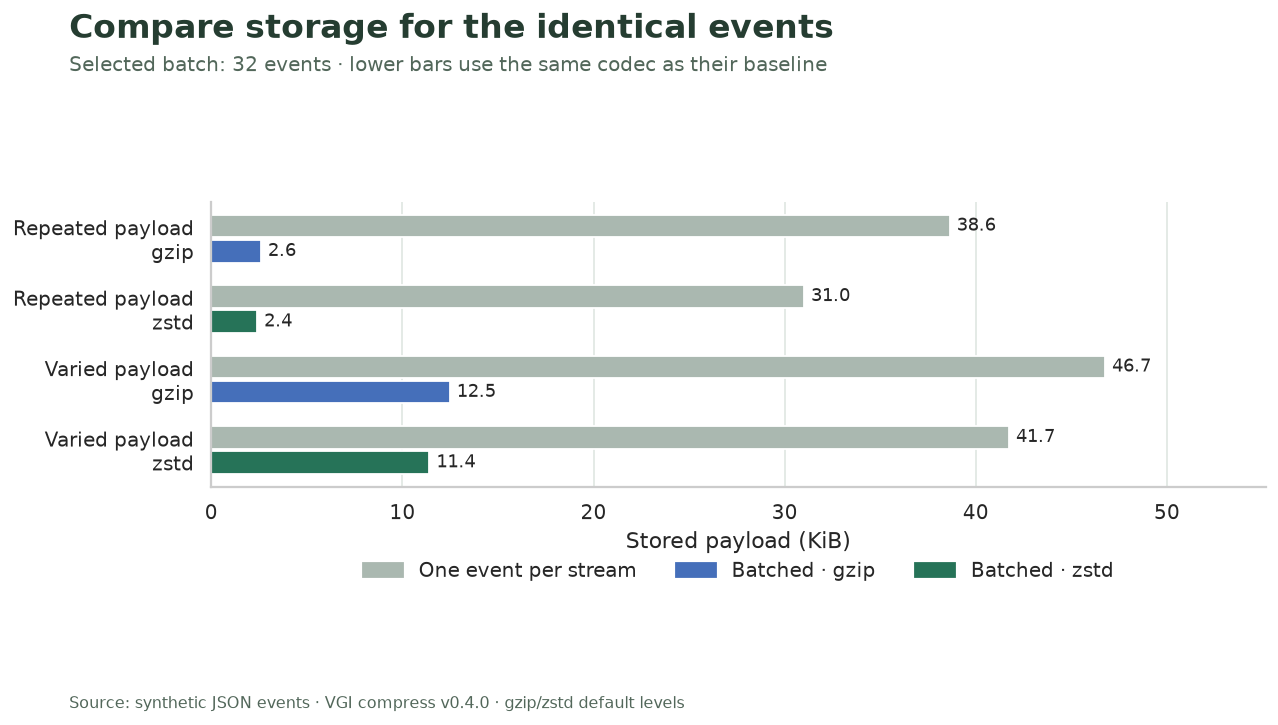

In [14]:
y = np.arange(len(comparison))
fig, ax = plt.subplots(figsize=(10.2, 5.6))
baseline = ax.barh(
    y - 0.18, comparison.individual_bytes / 1024, height=0.32, color="#aab8b0"
)
selected = ax.barh(
    y + 0.18,
    comparison.batched_bytes / 1024,
    height=0.32,
    color=[CODEC_COLORS[c] for c in comparison.codec],
)
ax.bar_label(baseline, fmt="%.1f", padding=4, fontsize=10)
ax.bar_label(selected, fmt="%.1f", padding=4, fontsize=10)
labels = [f"{r.kind}\n{r.codec}" for r in comparison.itertuples()]
ax.set(yticks=y, yticklabels=labels, xlabel="Stored payload (KiB)", ylabel="")
ax.invert_yaxis()
ax.set_xlim(
    0,
    max(comparison.individual_bytes.max(), comparison.batched_bytes.max())
    / 1024
    * 1.18,
)
ax.grid(axis="y", visible=False)
ax.legend(
    handles=[
        Patch(color="#aab8b0", label="One event per stream"),
        *[Patch(color=c, label=f"Batched · {k}") for k, c in CODEC_COLORS.items()],
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.20),
    ncol=3,
    frameon=False,
)
finish(
    fig,
    "Compare storage for the identical events",
    f"Selected batch: {EVENTS_PER_BATCH} events · lower bars use the same codec as their baseline",
    "selected-storage.png",
)

## Keep codec metadata even when detection succeeds

Our gzip and zstd batches have recognizable framing. A valid Brotli stream has
no such magic bytes, so the worker reports `unknown` for this final control.
Explicit decoding still recovers the source. Unknown format and corrupt payload
are different states; this is why the stored codec label remains part of the record.

In [15]:
%%sql
WITH sample AS (
 SELECT 'same bytes, known codec'::BLOB AS original,
        compress.main.compress(original, 'brotli') AS packed
)
SELECT compress.main.detect_codec(packed) AS detected,
       compress.main.is_valid(packed, 'brotli') AS valid_brotli,
       compress.main.decompress(packed, 'brotli', 1048576) = original AS exact_roundtrip
FROM sample;

,detected,valid_brotli,exact_roundtrip
0,unknown,True,True


## Experiment: make the selected batch four times larger

Change only **`EVENTS_PER_BATCH = 128`**, restart and run all. Predict how the
number of stored units and the saved-byte percentages will change. Compare the
selected comparison table, outlined points and paired bars. The full reference
curves and original raw byte totals should stay unchanged. Reset to **32**.

A larger batch is a storage and access-granularity choice. These fixed inputs
establish the byte tradeoff for this example; a production decision also needs
measurements of decode latency, update frequency and the application's retrieval unit.

In [16]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)